# 26 — Week 7: battery model and ramp-limiting MPC (RQ4)

**Question (RQ4):** how much does forecast quality reduce the ramp rate the grid sees when a battery behind the meter
is controlled by MPC?

**Design (provisional; `src/control/battery_mpc.py`).**
- 1-minute steps on the measured GPU power P(t) (valid minutes only; the controller restarts at every gap with
  SoC = 0.5). Grid power g = P − p_discharge + p_charge; SoC(k+1) = SoC(k) + (η·p_c − p_d/η)·Δt/E, η = 0.95,
  SoC ∈ [0.1, 0.9]; power limit P_max = 2·E kW (2C).
- Ramp limit **R = 1.0 kW/min** (main; ≈ 3% of the mean load per minute, between the train p95 0.82 and p99 1.50 kW of
  |ΔP|); sensitivity R = 0.5 and 2.0 kW/min at E = 5 kWh.
- MPC every minute, horizon 15 min, cvxpy (CLARABEL): minimise 1000·Σ ramp-violation slack + Σ (SoC − 0.5)² +
  0.01·Σ battery power. Only the first move is applied, on the measured P(t).
- **Scenarios:** `oracle` (true future), `model` (frozen LightGBM + covariates forecasts at 1/5/15 min, linearly
  interpolated to a 15-minute trajectory; seed 0), `persistence` (flat), `myopic` (no look-ahead = "no forecast"),
  plus `no battery` as the reference.
- **Metrics:** grid ramp violations (share of minutes with |Δg| > R), excess ramp energy, max and p99.9 ramp, battery
  throughput; **needed capacity** = smallest E in the grid with violation share ≤ 0.1%.
- **Validation → test:** the capacity grid is checked on validation (cells 3–4). Then a freeze record is written
  (cell 5) and the test month is simulated once (cell 6). The forecasts are the frozen Week 4 forecasts; nothing is
  refit.

**Run time:** about 1.5–2 min per simulated month and run; validation ≈ 40 min, test ≈ 55 min. Results are cached per
run in `experiments/week7_mpc/`, so an interrupted cell can simply be re-run. Keep the lid open (`caffeinate -dis`).
Save with Cmd+S after cell 8, then run cell 9 (export).


In [1]:
# Cell 1: setup
import sys, json, time, hashlib, subprocess, warnings
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import cvxpy as cp

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
from control import battery_mpc as B

print("cvxpy", cp.__version__, "| solvers", cp.installed_solvers())
assert "CLARABEL" in cp.installed_solvers()
R_MAIN = 1.0
R_SENS = [0.5, 2.0]
E_GRID = [1.0, 2.0, 5.0, 10.0, 20.0]
E_SENS = 5.0
SCEN = ["oracle", "model", "persistence", "myopic"]
MODEL = "lightgbm_cov"
VIOL_OK = 0.001
REP, FIG = ROOT / "reports" / "week7", ROOT / "reports" / "figures" / "week7"
CACHE = ROOT / "experiments" / "week7_mpc"
for d in (REP, FIG, CACHE):
    d.mkdir(parents=True, exist_ok=True)
FREEZE_F = REP / "mpc_test_freeze.json"
COL = {"no battery": "#52514e", "oracle": "#2a78d6", "model": "#eb6834", "persistence": "#1baf7a", "myopic": "#eda100"}
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6})

md_ = pl.read_parquet(ROOT / "data" / "processed" / "model_dataset.parquet")
P = md_["P_kW"].fill_null(np.nan).to_numpy().astype(float)
VALID = md_["valid"].to_numpy() & np.isfinite(P)
SPLIT = np.array(md_["split"].to_list(), dtype=object)
EP = md_["minute_epoch"].to_numpy()
SEGS = {s: B.segments(VALID & (SPLIT == s), min_len=60) for s in ("val", "test")}
for s, sg in SEGS.items():
    print(f"{s}: {len(sg)} segments, {sum(b - a for a, b in sg):,} minutes simulated "
          f"(of {int((VALID & (SPLIT == s)).sum()):,} valid)")
print("freeze record exists:", FREEZE_F.exists())

def forecast_dict(pred, model):
    """minute index -> (y1, y5, y15) where all three horizons exist."""
    w = (pred.filter(pl.col("model") == model).pivot(on="h", index="minute_epoch", values="yhat").drop_nulls())
    t = np.searchsorted(EP, w["minute_epoch"].to_numpy())
    return {int(i): (a, b, c) for i, a, b, c in zip(t, w["1"].to_numpy(), w["5"].to_numpy(), w["15"].to_numpy())}

VAL_PRED = pl.read_parquet(ROOT / "reports" / "classical" / "val_predictions.parquet").with_columns(pl.col("h").cast(pl.Utf8))
FC_VAL = forecast_dict(VAL_PRED, MODEL)
print(f"validation forecast trajectories ({MODEL}): {len(FC_VAL):,}")


cvxpy 1.9.3 | solvers ['CLARABEL', 'SCS', 'SCIPY', 'HIGHS', 'OSQP']
val: 2 segments, 42,636 minutes simulated (of 42,636 valid)
test: 2 segments, 42,636 minutes simulated (of 42,636 valid)
freeze record exists: False
validation forecast trajectories (lightgbm_cov): 42,547


In [2]:
# Cell 2: unit checks on synthetic data (no project data)
checks = []
n = 400
Ps = np.full(n, 30.0); Ps[200:] += 6.0                       # one 6 kW step at minute 200
seg = B.segments(np.ones(n, bool))
nb = B.ramp_metrics({"P": Ps, "first": np.r_[True, np.zeros(n - 1, bool)]}, 1.0, key="P")
checks.append(("no battery: one violation of 5 kW excess", nb["viol_steps"] == 1 and abs(nb["viol_excess_kW"] - 5) < 1e-9, nb["viol_steps"]))
res = {}
for sc in ("oracle", "persistence", "myopic"):
    m = B.MPC(5.0, 10.0, 1.0, N=1 if sc == "myopic" else 15)
    res[sc] = B.simulate(Ps, seg, sc, m)
    met = B.ramp_metrics(res[sc], 1.0)
    checks.append((f"{sc}: battery removes the step violation (max ramp <= R)", met["max_ramp"] <= 1.0 + 1e-4, round(met["max_ramp"], 4)))
r = res["oracle"]
d_soc = np.diff(np.r_[B.SOC_REF, r["soc"]])
exp = (B.ETA * r["pc"] - r["pd"] / B.ETA) * B.DT / 5.0
checks.append(("SoC follows the battery model exactly", np.allclose(d_soc, exp, atol=1e-9), None))
checks.append(("grid = P - pd + pc", np.allclose(r["g"], r["P"] - r["pd"] + r["pc"]), None))
checks.append(("oracle starts moving before the step (anticipation)", np.abs(r["g"][185:200] - 30).max() > 0.5, round(float(np.abs(r["g"][185:200] - 30).max()), 3)))
checks.append(("persistence cannot anticipate (g = P before the step)", np.abs(res["persistence"]["g"][185:200] - 30).max() < 0.05, None))
tr = B.trajectory_model(30.0, 31.0, 35.0, 40.0)
checks.append(("trajectory interpolation", np.allclose(tr[[0, 1, 3, 5, 10, 14]], [30, 31, 33, 35, 37.5, 39.5]), None))
checks.append(("segments", B.segments(np.array([1] * 70 + [0] * 5 + [1] * 30 + [0] + [1] * 61, bool)) == [(0, 70), (106, 167)], None))
for name, ok, val in checks:
    print(f"{'PASS' if ok else 'FAIL'}  {name}" + (f"  [{val}]" if val is not None else ""))
UNIT_OK = all(ok for _, ok, _ in checks)
print("\nALL UNIT CHECKS PASSED" if UNIT_OK else "\nUNIT CHECKS FAILED: stop and send this output")


PASS  no battery: one violation of 5 kW excess  [1]
PASS  oracle: battery removes the step violation (max ramp <= R)  [1.0]
PASS  persistence: battery removes the step violation (max ramp <= R)  [1.0]
PASS  myopic: battery removes the step violation (max ramp <= R)  [1.0]
PASS  SoC follows the battery model exactly
PASS  grid = P - pd + pc
PASS  oracle starts moving before the step (anticipation)  [2.512]
PASS  persistence cannot anticipate (g = P before the step)
PASS  trajectory interpolation
PASS  segments

ALL UNIT CHECKS PASSED


In [3]:
# Cell 3: validation sweep (cached per run; about 40 min)
assert UNIT_OK

def run(split, scen, E, R, fc):
    f = CACHE / f"{split}_{scen}_E{E:g}_R{R:g}.parquet"
    if f.exists():
        d = pl.read_parquet(f)
        return {k: d[k].to_numpy() for k in d.columns} | {"fallback": int(d["fallback"][0])}, True
    m = B.MPC(E, 2.0 * E, R, N=1 if scen == "myopic" else 15)
    t0 = time.time()
    r = B.simulate(P, SEGS[split], scen, m, forecasts=fc if scen == "model" else None)
    d = pl.DataFrame({k: r[k] for k in ("minute", "P", "g", "soc", "pc", "pd", "ok", "first")}).with_columns(pl.lit(r["fallback"]).alias("fallback"))
    d.write_parquet(f)
    print(f"  {split} {scen:11s} E={E:>4g} R={R:g}: {time.time() - t0:5.0f} s")
    return r, False

def table(split, fc, grid, Rs):
    rows = []
    nbm = None
    for R in Rs:
        base = {"P": P[np.concatenate([np.arange(a, b) for a, b in SEGS[split]])],
                "first": np.concatenate([np.r_[True, np.zeros(b - a - 1, bool)] for a, b in SEGS[split]])}
        nbm = B.ramp_metrics(base, R, key="P")
        rows.append({"split": split, "R": R, "E_kWh": 0.0, "scenario": "no battery", **nbm})
        for E in grid:
            for sc in SCEN:
                r, _ = run(split, sc, E, R, fc)
                rows.append({"split": split, "R": R, "E_kWh": E, "scenario": sc, **B.ramp_metrics(r, R),
                             "fallback": int(r["fallback"])})
    return pl.DataFrame(rows, infer_schema_length=None)

t0 = time.time()
VAL_TAB = table("val", FC_VAL, E_GRID, [R_MAIN])
VAL_TAB.write_csv(REP / "mpc_val.csv")
print(f"validation done in {(time.time() - t0) / 60:.1f} min")


  val oracle      E=   1 R=1:    44 s
  val model       E=   1 R=1:    44 s
  val persistence E=   1 R=1:    45 s
  val myopic      E=   1 R=1:    28 s
  val oracle      E=   2 R=1:    42 s
  val model       E=   2 R=1:    44 s
  val persistence E=   2 R=1:    43 s
  val myopic      E=   2 R=1:    26 s
  val oracle      E=   5 R=1:    43 s
  val model       E=   5 R=1:    42 s
  val persistence E=   5 R=1:    42 s
  val myopic      E=   5 R=1:    26 s
  val oracle      E=  10 R=1:    43 s
  val model       E=  10 R=1:    42 s
  val persistence E=  10 R=1:    46 s
  val myopic      E=  10 R=1:    27 s
  val oracle      E=  20 R=1:    46 s
  val model       E=  20 R=1:    48 s
  val persistence E=  20 R=1:    43 s
  val myopic      E=  20 R=1:    33 s
validation done in 13.3 min


shape: (21, 13)
┌─────┬───────┬─────────────┬────────────┬───┬─────────┬─────────┬─────────────┬──────────┐
│ R   ┆ E_kWh ┆ scenario    ┆ viol_steps ┆ … ┆ soc_min ┆ soc_max ┆ solver_fail ┆ fallback │
│ --- ┆ ---   ┆ ---         ┆ ---        ┆   ┆ ---     ┆ ---     ┆ ---         ┆ ---      │
│ f64 ┆ f64   ┆ str         ┆ i64        ┆   ┆ f64     ┆ f64     ┆ i64         ┆ i64      │
╞═════╪═══════╪═════════════╪════════════╪═══╪═════════╪═════════╪═════════════╪══════════╡
│ 1.0 ┆ 0.0   ┆ no battery  ┆ 1954       ┆ … ┆ null    ┆ null    ┆ null        ┆ null     │
│ 1.0 ┆ 1.0   ┆ oracle      ┆ 96         ┆ … ┆ 0.4222  ┆ 0.5856  ┆ 0           ┆ 0        │
│ 1.0 ┆ 1.0   ┆ model       ┆ 199        ┆ … ┆ 0.3595  ┆ 0.6942  ┆ 0           ┆ 89       │
│ 1.0 ┆ 1.0   ┆ persistence ┆ 202        ┆ … ┆ 0.3611  ┆ 0.6942  ┆ 0           ┆ 0        │
│ 1.0 ┆ 1.0   ┆ myopic      ┆ 194        ┆ … ┆ 0.1449  ┆ 0.9     ┆ 0           ┆ 0        │
│ 1.0 ┆ 2.0   ┆ oracle      ┆ 7          ┆ … ┆ 0.3806  ┆ 0.5916 

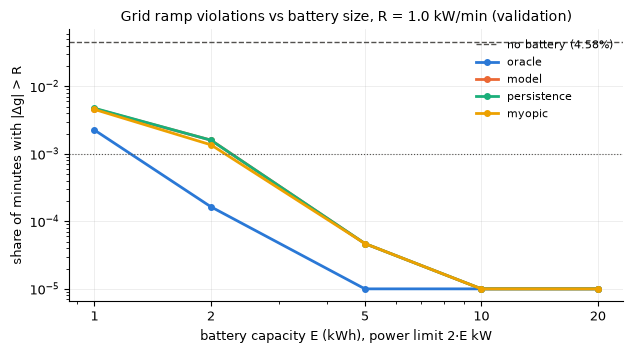

In [4]:
# Cell 4: validation results and needed capacity
SHOWM = ["R", "E_kWh", "scenario", "viol_steps", "viol_share", "viol_excess_kW", "max_ramp", "p999_ramp", "throughput_kWh",
         "soc_min", "soc_max", "solver_fail", "fallback"]
pl.Config.set_tbl_rows(60); pl.Config.set_tbl_width_chars(220)
print(VAL_TAB.select([c for c in SHOWM if c in VAL_TAB.columns]).with_columns(pl.col(pl.Float64).round(4)))

def needed(tab, R):
    out = {}
    for sc in SCEN:
        ok = tab.filter((pl.col("R") == R) & (pl.col("scenario") == sc) & (pl.col("viol_share") <= VIOL_OK)).sort("E_kWh")
        out[sc] = float(ok["E_kWh"][0]) if ok.height else None
    return out
NEED_VAL = needed(VAL_TAB, R_MAIN)
print(f"\nneeded capacity (violation share <= {VIOL_OK:.1%}), validation, R = {R_MAIN}: {NEED_VAL}")
if any(v is None for v in NEED_VAL.values()) or any(v == E_GRID[0] for v in NEED_VAL.values()):
    print("NOTE: a needed capacity is at an edge of the grid; the test grid stays as fixed in cell 1 (report this)")

def violation_figure(tab, split, fname):
    fig, ax = plt.subplots(figsize=(6.4, 3.6))
    t = tab.filter(pl.col("R") == R_MAIN)
    nbv = t.filter(pl.col("scenario") == "no battery")["viol_share"][0]
    ax.axhline(nbv, color=COL["no battery"], lw=1, ls="--", label=f"no battery ({nbv:.2%})")
    for sc in SCEN:
        s = t.filter(pl.col("scenario") == sc).sort("E_kWh")
        ax.plot(s["E_kWh"], np.maximum(s["viol_share"].to_numpy(), 1e-5), marker="o", ms=4, lw=2, color=COL[sc], label=sc)
    ax.axhline(VIOL_OK, color="#52514e", lw=0.8, ls=":")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(E_GRID, [f"{e:g}" for e in E_GRID])
    ax.set_xlabel("battery capacity E (kWh), power limit 2·E kW"); ax.set_ylabel("share of minutes with |Δg| > R")
    ax.set_title(f"Grid ramp violations vs battery size, R = {R_MAIN} kW/min ({split})", fontsize=10)
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout(); fig.savefig(FIG / fname, dpi=160, bbox_inches="tight"); plt.show()
violation_figure(VAL_TAB, "validation", "07_mpc_violations_val.png")


In [5]:
# Cell 5: freeze record (written BEFORE the test month is simulated)
assert UNIT_OK
def sha(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
w4 = [json.loads(p.read_text()) for p in sorted((ROOT / "reports" / "week4").glob("test_freeze*.json"))]
assert sha(ROOT / "reports" / "week4" / "test_predictions.parquet") in [r.get("test_predictions_sha256") for r in w4]
try:
    git = subprocess.run(["git", "rev-parse", "HEAD"], cwd=ROOT, capture_output=True, text=True).stdout.strip() or None
except Exception:  # noqa: BLE001
    git = None
files = ["reports/week4/test_predictions.parquet", "data/processed/model_dataset.parquet", "src/control/battery_mpc.py"]
freeze = {"frozen_at": time.strftime("%Y-%m-%d %H:%M:%S"), "git_head": git,
          "settings": {"R_main": R_MAIN, "R_sens": R_SENS, "E_grid": E_GRID, "E_sens": E_SENS, "Pmax": "2*E",
                       "eta": B.ETA, "soc": [B.SOC_MIN, B.SOC_MAX, B.SOC_REF], "weights": [B.W_VIOL, B.W_SOC, B.W_USE],
                       "horizon": 15, "solver": "CLARABEL", "model": MODEL, "seed": 0, "viol_ok": VIOL_OK},
          "validation_needed_capacity": NEED_VAL,
          "inputs_sha256": {f: sha(ROOT / f) for f in files}}
if FREEZE_F.exists():
    print("NOTE: an MPC freeze record already exists (the test month was simulated before); writing a second record")
    FREEZE_F = REP / f"mpc_test_freeze_{time.strftime('%Y%m%d_%H%M%S')}.json"
FREEZE_F.write_text(json.dumps(freeze, indent=1))
print(f"freeze record {FREEZE_F.name} | git {git}")


freeze record mpc_test_freeze.json | git 96597605437198fbfb9cb0a5da4aee2b50ccbbd4


In [6]:
# Cell 6: TEST month (once): main grid at R = 1 and the R sensitivity at E = 5 (about 55 min; cached per run)
assert FREEZE_F.exists()
TEST_PRED = (pl.read_parquet(ROOT / "reports" / "week4" / "test_predictions.parquet")
               .filter((pl.col("model") == MODEL) & (pl.col("seed") == 0)).with_columns(pl.col("h").cast(pl.Utf8)))
FC_TEST = forecast_dict(TEST_PRED, MODEL)
print(f"test forecast trajectories ({MODEL}): {len(FC_TEST):,}")
t0 = time.time()
TEST_TAB = pl.concat([table("test", FC_TEST, E_GRID, [R_MAIN]), table("test", FC_TEST, [E_SENS], R_SENS)], how="diagonal_relaxed")
TEST_TAB.write_csv(REP / "mpc_test.csv")
fr = json.loads(FREEZE_F.read_text())
fr["test_run_at"] = time.strftime("%Y-%m-%d %H:%M:%S")
fr["test_table_sha256"] = sha(REP / "mpc_test.csv")
FREEZE_F.write_text(json.dumps(fr, indent=1))
print(f"test done in {(time.time() - t0) / 60:.1f} min")


test forecast trajectories (lightgbm_cov): 42,547
  test oracle      E=   1 R=1:    46 s
  test model       E=   1 R=1:    45 s
  test persistence E=   1 R=1:    46 s
  test myopic      E=   1 R=1:    27 s
  test oracle      E=   2 R=1:    46 s
  test model       E=   2 R=1:    47 s
  test persistence E=   2 R=1:    48 s
  test myopic      E=   2 R=1:    27 s
  test oracle      E=   5 R=1:    48 s
  test model       E=   5 R=1:    60 s
  test persistence E=   5 R=1:    56 s
  test myopic      E=   5 R=1:    30 s
  test oracle      E=  10 R=1:    56 s
  test model       E=  10 R=1:    58 s
  test persistence E=  10 R=1:    59 s
  test myopic      E=  10 R=1:    36 s
  test oracle      E=  20 R=1:    60 s
  test model       E=  20 R=1:    60 s
  test persistence E=  20 R=1:    57 s
  test myopic      E=  20 R=1:    35 s
  test oracle      E=   5 R=0.5:    59 s
  test model       E=   5 R=0.5:    60 s
  test persistence E=   5 R=0.5:   134 s
  test myopic      E=   5 R=0.5:    27 s
  test

shape: (31, 13)
┌─────┬───────┬─────────────┬────────────┬───┬─────────┬─────────┬─────────────┬──────────┐
│ R   ┆ E_kWh ┆ scenario    ┆ viol_steps ┆ … ┆ soc_min ┆ soc_max ┆ solver_fail ┆ fallback │
│ --- ┆ ---   ┆ ---         ┆ ---        ┆   ┆ ---     ┆ ---     ┆ ---         ┆ ---      │
│ f64 ┆ f64   ┆ str         ┆ i64        ┆   ┆ f64     ┆ f64     ┆ i64         ┆ i64      │
╞═════╪═══════╪═════════════╪════════════╪═══╪═════════╪═════════╪═════════════╪══════════╡
│ 0.5 ┆ 0.0   ┆ no battery  ┆ 4517       ┆ … ┆ null    ┆ null    ┆ null        ┆ null     │
│ 0.5 ┆ 5.0   ┆ model       ┆ 0          ┆ … ┆ 0.2519  ┆ 0.6478  ┆ 0           ┆ 89       │
│ 0.5 ┆ 5.0   ┆ myopic      ┆ 23         ┆ … ┆ 0.1     ┆ 0.9     ┆ 0           ┆ 0        │
│ 0.5 ┆ 5.0   ┆ oracle      ┆ 0          ┆ … ┆ 0.466   ┆ 0.553   ┆ 0           ┆ 0        │
│ 0.5 ┆ 5.0   ┆ persistence ┆ 0          ┆ … ┆ 0.2521  ┆ 0.6482  ┆ 0           ┆ 0        │
│ 1.0 ┆ 0.0   ┆ no battery  ┆ 945        ┆ … ┆ null    ┆ null   

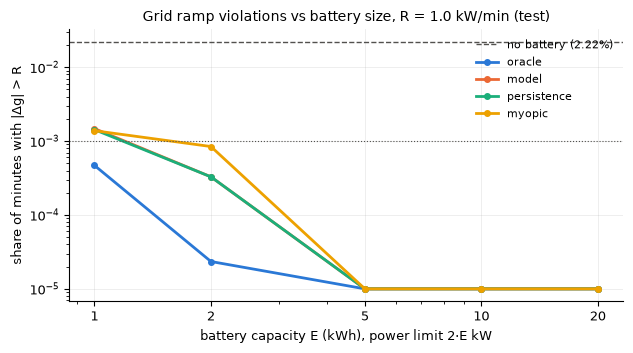

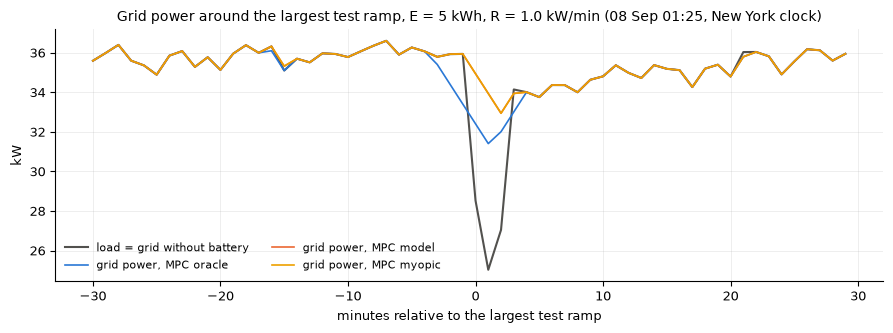

In [7]:
# Cell 7: test results: violations, needed capacity, value of the forecast; figures
print(TEST_TAB.select([c for c in SHOWM if c in TEST_TAB.columns]).sort("R", "E_kWh", "scenario").with_columns(pl.col(pl.Float64).round(4)))
NEED_TEST = needed(TEST_TAB, R_MAIN)
print(f"\nneeded capacity (violation share <= {VIOL_OK:.1%}), test, R = {R_MAIN}: {NEED_TEST}  (validation: {NEED_VAL})")
main = TEST_TAB.filter(pl.col("R") == R_MAIN)
val_ = []
for E in E_GRID:
    g = {r["scenario"]: r for r in main.filter(pl.col("E_kWh") == E).to_dicts()}
    my, pe, mo, orc = (g[s]["viol_excess_kW"] for s in ("myopic", "persistence", "model", "oracle"))
    gap = my - orc
    val_.append({"E_kWh": E, "excess_myopic": my, "excess_persistence": pe, "excess_model": mo, "excess_oracle": orc,
                 "model_share_of_oracle_gain": (my - mo) / gap if gap > 1e-9 else float("nan"),
                 "persistence_share_of_oracle_gain": (my - pe) / gap if gap > 1e-9 else float("nan")})
VALUE = pl.DataFrame(val_)
VALUE.write_csv(REP / "mpc_value_of_forecast_test.csv")
print("\nexcess ramp (kW summed over violating minutes) and the share of the oracle's improvement over 'myopic' that each forecast achieves:")
print(VALUE.with_columns(pl.col(pl.Float64).round(3)))
violation_figure(TEST_TAB, "test", "08_mpc_violations_test.png")

# example: the largest test load ramp, simulated with E = 5 kWh
E_EX = E_SENS
P_seg = np.concatenate([np.arange(a, b) for a, b in SEGS["test"]])
dP = np.abs(np.diff(P[P_seg])); dP[np.diff(P_seg) != 1] = 0
t_ev = int(P_seg[np.argmax(dP) + 1])
win = (t_ev - 30, t_ev + 30)
fig, ax = plt.subplots(figsize=(9, 3.4))
m_ = (P_seg >= win[0]) & (P_seg < win[1])
ax.plot(np.arange(win[0], win[1]) - t_ev, P[win[0]:win[1]], color=COL["no battery"], lw=1.5, label="load = grid without battery")
for sc in ("oracle", "model", "myopic"):
    r, _ = run("test", sc, E_EX, R_MAIN, FC_TEST)
    k = (r["minute"] >= win[0]) & (r["minute"] < win[1])
    ax.plot(r["minute"][k] - t_ev, r["g"][k], color=COL[sc], lw=1.2, label=f"grid power, MPC {sc}")
ax.set_xlabel("minutes relative to the largest test ramp"); ax.set_ylabel("kW")
ax.set_title(f"Grid power around the largest test ramp, E = {E_EX:g} kWh, R = {R_MAIN} kW/min "
             f"({time.strftime('%d %b %H:%M', time.gmtime(EP[t_ev]))}, New York clock)", fontsize=10)
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig(FIG / "09_mpc_ramp_event_test.png", dpi=160, bbox_inches="tight"); plt.show()


In [8]:
# Cell 8: summary JSON and the Week 7 checklist
summ = {"freeze_record": FREEZE_F.name, "R_main": R_MAIN, "E_grid": E_GRID, "needed_capacity_val": NEED_VAL,
        "needed_capacity_test": NEED_TEST, "val": VAL_TAB.to_dicts(), "test": TEST_TAB.to_dicts(), "value": VALUE.to_dicts()}
(REP / "mpc_summary.json").write_text(json.dumps(summ, indent=1, default=str))
chk = [("[main] battery model SoC(k+1) = SoC(k) + eta*P_b*dt/E with power and energy limits", UNIT_OK),
       ("[main] MPC with cvxpy, 15-minute horizon, ramp limit on P_grid = P_dc - P_b", UNIT_OK),
       ("[main] four scenarios: oracle, best model, naive (persistence), no forecast (myopic)", set(SCEN) <= set(TEST_TAB["scenario"].unique().to_list())),
       ("[main] metrics: max ramp, violations, needed battery capacity", True),
       ("[main] split conformal (notebook 24)", (REP / "conformal_summary.json").exists()),
       ("[main] SHAP on LightGBM (notebook 25)", (REP / "shap_summary.json").exists())]
for k, v in chk:
    print(f"{'DONE' if v else 'CHECK'}  {k}")
print("supplementary QAOA job shifting: not started (dropped first under the plan's rule)")


DONE  [main] battery model SoC(k+1) = SoC(k) + eta*P_b*dt/E with power and energy limits
DONE  [main] MPC with cvxpy, 15-minute horizon, ramp limit on P_grid = P_dc - P_b
DONE  [main] four scenarios: oracle, best model, naive (persistence), no forecast (myopic)
DONE  [main] metrics: max ramp, violations, needed battery capacity
DONE  [main] split conformal (notebook 24)
DONE  [main] SHAP on LightGBM (notebook 25)
supplementary QAOA job shifting: not started (dropped first under the plan's rule)


In [10]:
# Cell 9: export outputs (save the notebook first with Cmd+S after cell 8 has finished, then run this cell)
%run ../src/tools/nb_outputs_to_md.py 26_week7_mpc.ipynb


written 26_week7_mpc_outputs.md | code cells 10 | figures 3 in 26_week7_mpc_outputs_figures
